<a href="https://colab.research.google.com/github/ishitamunshi/world_model_stacking/blob/main/notebooks/late_horizon_scoring.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Planning Baseline

Switch the runtime to a GPU (**Runtime → Change runtime type → GPU**), then click **Runtime → Run all**.

This notebook downloads the simulator code, the frozen world model and policy, and the subgoal images, then runs validation scene `100038` twice: once with the policy alone and once with the baseline planner. With the default seed on our GPUs, the policy alone stacks one box and the planner stacks two; on a Colab T4 the result can differ slightly because it runs in float16. The whole notebook takes about 10 to 15 minutes.

After running it once, edit `GoalPlanningAgent` in the planner cell below to try your own planner.

In [1]:
import os, subprocess, sys
os.environ["MUJOCO_GL"] = "egl"
os.environ["MUJOCO_EGL_DEVICE_ID"] = "0"
os.environ["PYOPENGL_PLATFORM"] = "egl"
os.environ["HF_HUB_DISABLE_XET"] = "1"

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    print("installing system libraries", flush=True)
    env = dict(os.environ, DEBIAN_FRONTEND="noninteractive")
    subprocess.check_call(["apt-get", "update", "-qq"], env=env)
    subprocess.check_call(
        ["apt-get", "install", "-y", "-qq", "libegl1", "libgl1", "libgles2", "libglib2.0-0", "ffmpeg"],
        env=env,
    )

def missing(module):
    try:
        __import__(module)
        return False
    except Exception:
        return True

packages = []
if missing("mujoco"):
    packages.append("mujoco>=3.3,<4")
if missing("imageio_ffmpeg"):
    packages.append("imageio[ffmpeg]>=2.30")
if missing("huggingface_hub"):
    packages.append("huggingface_hub>=0.26")
if missing("matplotlib"):
    packages.append("matplotlib")
if packages:
    print("installing", ", ".join(packages), flush=True)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade-strategy", "only-if-needed", *packages])

import torch
if not torch.cuda.is_available():
    raise RuntimeError("No GPU is visible. In Colab: Runtime → Change runtime type → GPU, then Runtime → Run all.")
print("cuda", torch.cuda.get_device_name(0), flush=True)


installing system libraries
installing mujoco>=3.3,<4
cuda Tesla T4


In [2]:
import os, sys, tarfile
from pathlib import Path
os.environ["MUJOCO_GL"] = "egl"
os.environ["HF_HUB_DISABLE_XET"] = "1"

def find_root():
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "assignment" / "training" / "planning" / "agent.py").exists():
            return cand
    return None

ROOT = find_root()
if ROOT is None:
    dest = Path("/content") if Path("/content").exists() else Path("/tmp")
    ROOT = dest / "world-model-gym"
    marker = ROOT / "assignment" / "training" / "planning" / "agent.py"
    if not marker.exists():
        print("downloading code", flush=True)
        from huggingface_hub import hf_hub_download
        archive = hf_hub_download("YongYong/cis6280-stack-world-models-v2", "code/world-model-gym.tar", repo_type="model")
        with tarfile.open(archive) as tar:
            try:
                tar.extractall(dest, filter="data")
            except TypeError:
                tar.extractall(dest)
    if not marker.exists():
        raise FileNotFoundError(f"code download did not produce {marker}")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
hand = ROOT / "assets" / "sharpa" / "wave_01" / "right_sharpa_wave" / "right_sharpa_wave.xml"
if not hand.exists():
    print("downloading hand assets", flush=True)
    __import__("subprocess").check_call([sys.executable, "scripts/fetch_assets.py"])
import assignment.training.planning.agent
print("code", ROOT, flush=True)

from assignment.training.data.task import StackTaskEnv, TaskConfig
_env = StackTaskEnv(TaskConfig(target_count=4, horizon=10, terminate_on_ground=False), 100038)
_env.reset(("init", 100038))
_env.env.resolution = 128
# render() returns the (front, side) camera tuple, each of shape (128, 128, 3).
_frames = list(_env.env.render())
_env.close()
print("render", _frames[0].shape, flush=True)

downloading code


world-model-gym.tar:   0%|          | 0.00/17.7M [00:00<?, ?B/s]

code /content/world-model-gym
render (128, 128, 3)


In [3]:
import os, shutil
from pathlib import Path
os.environ["HF_HUB_DISABLE_XET"] = "1"
import torch
from huggingface_hub import hf_hub_download

CKPT = Path("/content/stack-baseline") if Path("/content").exists() else Path("/tmp/stack-baseline")
CKPT.mkdir(parents=True, exist_ok=True)
WM = CKPT / "smwm-c3.pt"
POLICY = CKPT / "df-smwm-c1-sigma04.pt"
GOALS = CKPT / "goals-every80.npz"

def fetch(repo, filename, dest, repo_type):
    if dest.exists() and dest.stat().st_size > 0:
        print("already downloaded", dest.name, flush=True)
        return dest
    print("downloading", filename, flush=True)
    src = hf_hub_download(repo, filename, repo_type=repo_type)
    shutil.copyfile(src, dest)
    return dest

fetch("YongYong/cis6280-stack-world-models-v2", "jepa/smwm-c3/model.pt", WM, "model")
fetch("YongYong/cis6280-stack-world-models-v2", "policy/df-smwm-c1-sigma04/policy.pt", POLICY, "model")
fetch("YongYong/cis6280-stack-datasets-v2", "goals/scripted-val100-every80/goals.npz", GOALS, "dataset")

# Point the policy checkpoint's encoder field to the local world-model file.
ckpt = torch.load(POLICY, map_location="cpu", weights_only=False)
ckpt["info"]["encoder"] = str(WM.resolve())
torch.save(ckpt, POLICY)
print("weights ready", WM.stat().st_size, POLICY.stat().st_size, GOALS.stat().st_size, flush=True)

downloading jepa/smwm-c3/model.pt


model.pt:   0%|          | 0.00/73.4M [00:00<?, ?B/s]

downloading policy/df-smwm-c1-sigma04/policy.pt


policy.pt:   0%|          | 0.00/157M [00:00<?, ?B/s]

downloading goals/scripted-val100-every80/goals.npz


goals.npz:   0%|          | 0.00/34.1M [00:00<?, ?B/s]

weights ready 73352395 156956837 34086423


## Subgoals

These are the subgoal images for scene `100038`, taken every 8 seconds from a scripted run. Each image shows the front wrist camera on the left and the side wrist camera on the right.

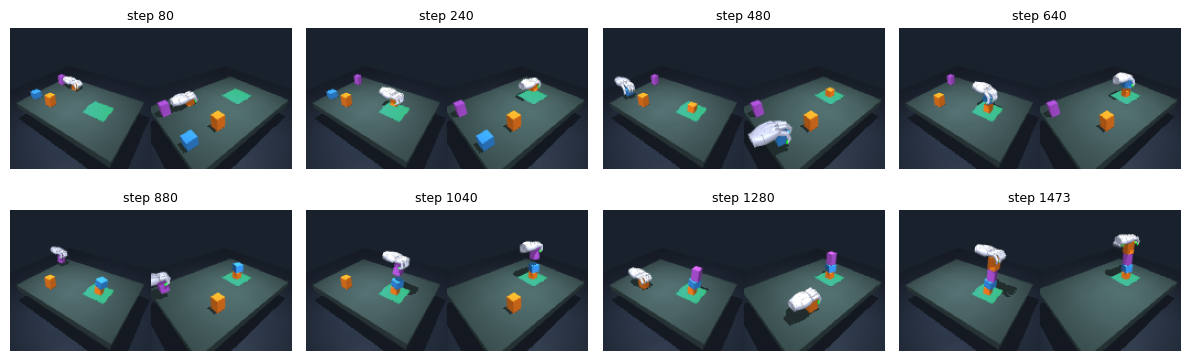

19 subgoals, every 80 control steps


In [4]:
import numpy as np
import matplotlib.pyplot as plt

SEED = 100038
with np.load(GOALS) as goals:
    index = list(goals["seeds"]).index(SEED)
    count = int(goals["sub_count"][index])
    frames = goals["sub_frames"][index, :count]
    steps = goals["sub_steps"][index, :count]
shown = np.linspace(0, count - 1, num=min(count, 8), dtype=int)
fig, axes = plt.subplots(2, 4, figsize=(12, 4))
for ax, i in zip(axes.ravel(), shown):
    ax.imshow(frames[i])
    ax.set_title(f"step {int(steps[i])}", fontsize=9)
    ax.axis("off")
for ax in axes.ravel()[len(shown):]:
    ax.axis("off")
fig.tight_layout()
plt.show()
print(f"{count} subgoals, every 80 control steps")


## EXPERIMENT 2

In [6]:

import numpy as np
import torch

from assignment.training.data.cache import RAW_ACTION_DIM, STRIDE
from assignment.training.planning.agent import LatentPolicyAgent


# ============================================================
# EXPERIMENT 2: LATE-HORIZON SCORING
# ============================================================

def late_horizon_score(pred, goal, alpha=0.10, last_k=4):
    """
    pred: (N, H, 192) predicted latent trajectories
    goal: (192,) target latent
    alpha: importance of late-horizon scoring
    last_k: number of final predicted states to evaluate

    Returns one cost per candidate.
    Lower cost is better.
    """
    if pred.ndim != 3 or goal.ndim != 1:
        raise ValueError("Expected pred [N,H,D] and goal [D]")

    if pred.shape[-1] != goal.numel():
        raise ValueError("Latent dimensions do not match")

    if not 0.0 <= alpha <= 1.0:
        raise ValueError("alpha must be between 0 and 1")

    if not 1 <= last_k <= pred.shape[1]:
        raise ValueError("Invalid last_k")

    distances = (
        pred.float() - goal.float()
    ).square().sum(dim=-1)

    terminal_cost = distances[:, -1]

    late_cost = distances[:, -last_k:].mean(dim=1)

    total_cost = (
        (1.0 - alpha) * terminal_cost
        + alpha * late_cost
    )

    return total_cost


# ============================================================
# NEW PLANNER
# ============================================================

class LateHorizonPlanningAgent(LatentPolicyAgent):

    def __init__(
        self,
        policy_path,
        device="cuda",
        candidates=16,
        tau=0.25,
        alpha=0.10,
        last_k=4,
        **kwargs,
    ):
        super().__init__(policy_path, device, **kwargs)

        self.candidates = int(candidates)
        self.tau = float(tau)
        self.alpha = float(alpha)
        self.last_k = int(last_k)

        if not 1 <= self.last_k <= self.generate:
            raise ValueError("last_k must be <= generate")

        self.goals = None
        self.last_score = None
        self.score_call_count = 0

    def reset(self, goal_frames=None, init_frame=None, seed=None):

        if goal_frames is not None and init_frame is None:
            raise ValueError("init_frame is required")

        super().reset(seed)

        self.frames = []
        self.executed = []
        self.index = 0

        self.last_distance = None
        self.last_score = None
        self.score_call_count = 0

        self.goals = None
        self.gap = None

        if goal_frames is not None:

            self.goals = self._encode(
                np.asarray(goal_frames)
            )

            previous_goals = torch.cat([
                self._encode(np.asarray(init_frame)[None]),
                self.goals[:-1],
            ])

            self.gap = (
                self.goals - previous_goals
            ).square().sum(-1)

    def goal_index(self, z):

        while (
            self.index < len(self.goals) - 1
            and (z - self.goals[self.index]).square().sum()
            < self.tau * self.gap[self.index]
        ):
            self.index += 1

        return self.index

    @torch.no_grad()
    def _encode(self, frames):

        x = torch.from_numpy(
            np.ascontiguousarray(frames)
        ).to(self.device)[:, None]

        with self._autocast():
            return self.encoder.encode(x)[:, 0].float()

    @torch.no_grad()
    def step(self, frame):

        if self.goals is None:
            raise RuntimeError("Call reset() before step()")

        # 1. Encode the current observation.
        z = self._encode(frame[None])[0]

        ctx = self.encoder.cfg.context

        self.frames = (
            self.frames + [z]
        )[-ctx:]

        self.history = (
            self.history + [(z - self.z_mean) / self.z_std]
        )[-self.policy.cfg.context:]

        goal = self.goals[self.goal_index(z)]

        if not self.queue:

            # 2. Sample candidate actions.
            pctx = (
                [self.history[0]]
                * (self.policy.cfg.context - len(self.history))
                + self.history
            )

            n = self.candidates

            blocks = self.policy.sample(
                torch.stack(pctx)[None].expand(n, -1, -1),
                self.generate,
                self.n_steps,
                self.lag,
                self.generator,
            )

            best = 0

            if n > 1:

                # 3. Roll out candidates through world model.
                past = (
                    self.executed[
                        len(self.executed) - len(self.frames) + 1:
                    ]
                    if len(self.frames) > 1
                    else []
                )

                actions = (
                    torch.cat([
                        torch.stack(past)[None].expand(n, -1, -1),
                        blocks,
                    ], dim=1)
                    if past else blocks
                )

                with self._autocast():

                    pred = self.encoder.rollout(
                        torch.stack(self.frames)[None].expand(
                            n, -1, -1
                        ),
                        self.encoder.action_encoder(actions),
                        self.generate,
                    )

                # Original terminal distance, for logging.
                self.last_distance = (
                    pred[:, -1].float() - goal
                ).square().sum(-1)

                # 4. NEW late-horizon cost function.
                self.last_score = late_horizon_score(
                    pred,
                    goal,
                    alpha=self.alpha,
                    last_k=self.last_k,
                )

                best = int(self.last_score.argmin().item())

                self.score_call_count += 1

            # 5. Convert selected candidate to raw actions.
            raw = np.clip(
                blocks[best, :self.execute].cpu().numpy()
                * self.a_std + self.a_mean,
                -1,
                1,
            )

            self.queue = list(
                raw.reshape(-1, STRIDE, RAW_ACTION_DIM)
            )

        # 6. Execute the next action block.
        block = self.queue.pop(0)

        self.executed.append(
            torch.from_numpy(
                (block.reshape(-1) - self.a_mean)
                / self.a_std
            ).to(self.device)
        )

        return block

In [7]:

# ============================================================
# EXPERIMENT 2: SCORING FUNCTION TEST
# ============================================================

torch.manual_seed(42)

pred_test = torch.randn(16, 16, 192, device="cuda")
goal_test = torch.randn(192, device="cuda")

terminal = (
    pred_test[:, -1] - goal_test
).square().sum(-1)

# Alpha = 0 must reproduce terminal scoring.
for k in [2, 4, 8]:
    torch.testing.assert_close(
        late_horizon_score(
            pred_test, goal_test,
            alpha=0.0, last_k=k,
        ),
        terminal,
    )

# K = 1 must also reproduce terminal scoring.
for alpha in [0.10, 0.25]:
    torch.testing.assert_close(
        late_horizon_score(
            pred_test, goal_test,
            alpha=alpha, last_k=1,
        ),
        terminal,
    )

scores = late_horizon_score(
    pred_test, goal_test,
    alpha=0.10, last_k=4,
)

assert scores.shape == (16,)
assert torch.isfinite(scores).all()

print("PASS: alpha=0 matches terminal baseline")
print("PASS: K=1 matches terminal baseline")
print("PASS: output has one finite score per candidate")


PASS: alpha=0 matches terminal baseline
PASS: K=1 matches terminal baseline
PASS: output has one finite score per candidate


In [8]:

# ============================================================
# EXPERIMENT 2: MULTI-SCENE EVALUATION
# ============================================================

import csv
import gc
import time
from pathlib import Path

from google.colab import drive
from assignment.training.data.signals import row_hand_parts
from assignment.training.data.task import StackTaskEnv, TaskConfig

# Connect Google Drive.
drive.mount("/content/drive")

# ------------------------------------------------------------
# 1. RESULT DIRECTORIES
# ------------------------------------------------------------

ROOT_RESULTS = Path(
    "/content/drive/MyDrive/world_model_stacking"
)

OLD_RESULTS = ROOT_RESULTS / "multiscene_eval"
NEW_RESULTS = ROOT_RESULTS / "late_horizon_eval"

NEW_RESULTS.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. USE THE SAME FIVE SCENES AS EXPERIMENT 1
# ------------------------------------------------------------

baseline_paths = sorted(
    OLD_RESULTS.glob("scene_*_alpha_000.csv")
)

SCENES = sorted({
    int(p.stem.split("_")[1])
    for p in baseline_paths
})[:5]

if len(SCENES) != 5:
    raise RuntimeError(
        f"Expected 5 baseline scenes, found {len(SCENES)}"
    )

# Make sure all Experiment 1 results exist.
for seed in SCENES:
    for tag in ["000", "010", "025"]:

        path = OLD_RESULTS / (
            f"scene_{seed}_alpha_{tag}.csv"
        )

        if not path.exists():
            raise FileNotFoundError(path)

with np.load(GOALS) as stored_goals:
    valid_seeds = set(
        int(s) for s in stored_goals["seeds"]
    )

assert set(SCENES).issubset(valid_seeds)

# ------------------------------------------------------------
# 3. EXPERIMENT CONFIGURATION
# ------------------------------------------------------------

LATE_ALPHA = 0.10
K_VALUES = [2, 4, 8]
HORIZON = 1795

print("Development scenes:", SCENES)
print("K values:", K_VALUES)
print("Alpha:", LATE_ALPHA)
print("Total simulations:", len(SCENES) * len(K_VALUES))
print("Saving to:", NEW_RESULTS)


# ------------------------------------------------------------
# 4. SINGLE EPISODE EVALUATION
# ------------------------------------------------------------

def evaluate_late(scene_seed, last_k):

    scene_seed = int(scene_seed)

    with np.load(GOALS) as goals_file:

        indices = np.flatnonzero(
            goals_file["seeds"] == scene_seed
        )

        if len(indices) != 1:
            raise ValueError(
                f"Invalid scene: {scene_seed}"
            )

        idx = int(indices[0])
        n_goals = int(goals_file["sub_count"][idx])

        goal_frames = goals_file[
            "sub_frames"
        ][idx, :n_goals].copy()

        init_frame = goals_file[
            "init_frames"
        ][idx].copy()

    # Create late-horizon planning agent.
    agent = LateHorizonPlanningAgent(
        str(POLICY),
        "cuda",
        candidates=16,
        generate=16,
        execute=1,
        tau=0.25,
        alpha=LATE_ALPHA,
        last_k=last_k,
    )

    agent.reset(
        goal_frames,
        init_frame,
        seed=scene_seed,
    )

    # Initialize the simulator.
    env = StackTaskEnv(
        TaskConfig(
            target_count=4,
            horizon=HORIZON,
            terminate_on_ground=False,
        ),
        scene_seed,
    )

    env.reset(("init", scene_seed))
    env.env.resolution = 128

    peak = 0
    final = 0
    executed = 0
    first_placement = None
    grasped = False

    started = time.perf_counter()

    try:
        for t in range(HORIZON):

            if t % STRIDE == 0:

                frame = np.concatenate(
                    list(env.env.render()),
                    axis=1,
                )

                block = agent.step(frame)

            # Execute current action.
            _, _, terminated, truncated, info = env.step(
                block[t % STRIDE]
            )

            executed = t + 1

            # Record stacking metrics.
            final = int(info["placed"])
            peak = max(peak, final)

            if first_placement is None and final >= 1:
                first_placement = executed

            grasped = grasped or bool(
                (
                    row_hand_parts(
                        env.env.history[-1]
                    )[0] >= 2
                ).any()
            )

            if terminated or truncated:
                break

    finally:
        env.close()

    elapsed = (
        time.perf_counter() - started
    ) / 60.0

    return {
        "scene_seed": scene_seed,
        "sampler_seed": scene_seed,
        "method": f"late_{last_k}",
        "last_k": int(last_k),
        "alpha": LATE_ALPHA,
        "candidates": 16,
        "tau": 0.25,
        "horizon": HORIZON,
        "max_boxes_stacked": peak,
        "final_boxes_stacked": final,
        "stack_loss": peak - final,
        "grasp_success": int(grasped),
        "first_placement_step": first_placement,
        "executed_steps": executed,
        "runtime_minutes": round(elapsed, 3),
        "scoring_calls": agent.score_call_count,
    }


# ------------------------------------------------------------
# 5. RUN THE EXPERIMENTS
# ------------------------------------------------------------

jobs = [
    (seed, k)
    for seed in SCENES
    for k in K_VALUES
]

for i, (seed, k) in enumerate(jobs, start=1):

    output = NEW_RESULTS / (
        f"scene_{seed}_late_{k:02d}_alpha_010.csv"
    )

    # Skip runs already saved in Drive.
    if output.exists():
        print(
            f"[{i}/{len(jobs)}] SKIP {output.name}",
            flush=True,
        )
        continue

    print(
        f"[{i}/{len(jobs)}] "
        f"Running scene={seed}, K={k}",
        flush=True,
    )

    result = evaluate_late(seed, k)

    # Save after each complete episode.
    temporary = output.with_suffix(".csv.tmp")

    with temporary.open("w", newline="") as f:

        writer = csv.DictWriter(
            f,
            fieldnames=list(result),
        )

        writer.writeheader()
        writer.writerow(result)

    temporary.replace(output)

    print(
        f"SAVED scene={seed}, K={k}: "
        f"peak={result['max_boxes_stacked']}, "
        f"final={result['final_boxes_stacked']}",
        flush=True,
    )

    gc.collect()
    torch.cuda.empty_cache()

print("Experiment 2 complete")


Mounted at /content/drive
Development scenes: [100035, 100057, 100060, 100069, 100072]
K values: [2, 4, 8]
Alpha: 0.1
Total simulations: 15
Saving to: /content/drive/MyDrive/world_model_stacking/late_horizon_eval
[1/15] Running scene=100035, K=2
SAVED scene=100035, K=2: peak=2, final=2
[2/15] Running scene=100035, K=4
SAVED scene=100035, K=4: peak=3, final=3
[3/15] Running scene=100035, K=8
SAVED scene=100035, K=8: peak=1, final=1
[4/15] Running scene=100057, K=2
SAVED scene=100057, K=2: peak=0, final=0
[5/15] Running scene=100057, K=4
SAVED scene=100057, K=4: peak=0, final=0
[6/15] Running scene=100057, K=8
SAVED scene=100057, K=8: peak=0, final=0
[7/15] Running scene=100060, K=2
SAVED scene=100060, K=2: peak=2, final=1
[8/15] Running scene=100060, K=4
SAVED scene=100060, K=4: peak=1, final=1
[9/15] Running scene=100060, K=8
SAVED scene=100060, K=8: peak=1, final=1
[10/15] Running scene=100069, K=2
SAVED scene=100069, K=2: peak=0, final=0
[11/15] Running scene=100069, K=4
SAVED scene=

AGGREGATE RESULTS: 5 matching scenes


,scenes,mean_peak,mean_final,mean_stack_loss,success_ge_2,success_ge_3,mean_runtime_min
method,,,,,,,
terminal_baseline,5,0.8,0.8,0.0,0.0,0.0,5.265
full_alpha_010,5,1.4,0.6,0.8,60.0,20.0,5.323
full_alpha_025,5,1.4,1.0,0.4,60.0,0.0,5.303
late_2,5,1.0,0.6,0.4,40.0,0.0,5.437
late_4,5,1.2,1.2,0.0,40.0,20.0,5.425
late_8,5,0.8,0.8,0.0,20.0,0.0,5.306


PAIRED PEAK-BOX DIFFERENCES


,late_2_vs_terminal,late_4_vs_terminal,late_8_vs_terminal,late_2_vs_full_010,late_4_vs_full_010,late_8_vs_full_010
scene_seed,,,,,,
100035.0,1.0,2.0,0.0,-1.0,0.0,-2.0
100057.0,-1.0,-1.0,-1.0,0.0,0.0,0.0
100060.0,1.0,0.0,0.0,0.0,-1.0,-1.0
100069.0,0.0,0.0,0.0,0.0,0.0,0.0
100072.0,0.0,1.0,1.0,-1.0,0.0,0.0


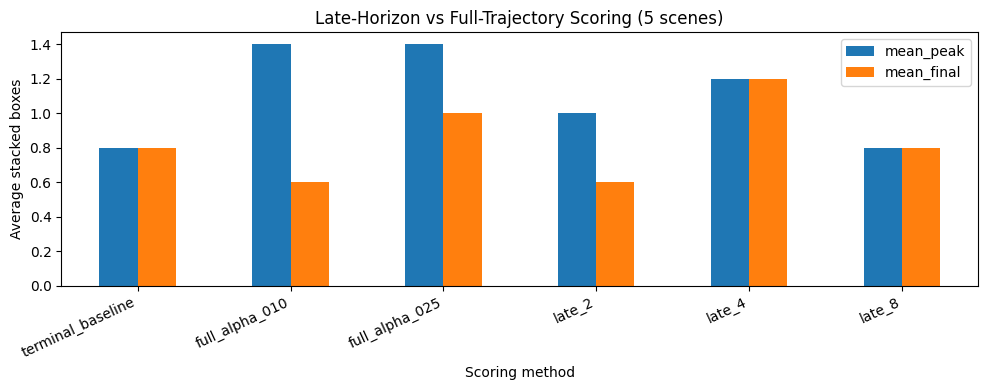

Saved results in: /content/drive/MyDrive/world_model_stacking/late_horizon_eval


In [9]:

# ============================================================
# EXPERIMENT 2: RESULTS AND COMPARISON
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

records = []

for seed in SCENES:

    # Load Experiment 1 results.
    for tag, label in [
        ("000", "terminal_baseline"),
        ("010", "full_alpha_010"),
        ("025", "full_alpha_025"),
    ]:

        path = OLD_RESULTS / (
            f"scene_{seed}_alpha_{tag}.csv"
        )

        if path.exists():

            r = pd.read_csv(path).iloc[0].to_dict()
            r["method"] = label
            records.append(r)

    # Load Experiment 2 results.
    for k in K_VALUES:

        path = NEW_RESULTS / (
            f"scene_{seed}_late_{k:02d}_alpha_010.csv"
        )

        if path.exists():

            r = pd.read_csv(path).iloc[0].to_dict()
            r["method"] = f"late_{k}"
            records.append(r)

data = pd.DataFrame(records)

methods = [
    "terminal_baseline",
    "full_alpha_010",
    "full_alpha_025",
    "late_2",
    "late_4",
    "late_8",
]

# ------------------------------------------------------------
# 1. KEEP ONLY FULLY COMPLETED SCENES
# ------------------------------------------------------------

counts = data.groupby(
    "scene_seed"
)["method"].nunique()

complete_seeds = counts[
    counts == len(methods)
].index

paired = data[
    data["scene_seed"].isin(complete_seeds)
].copy()

if paired.empty:
    raise RuntimeError(
        "No fully paired scenes. Run Cell 3 first."
    )

paired["stack_loss"] = (
    paired["max_boxes_stacked"]
    - paired["final_boxes_stacked"]
)

# ------------------------------------------------------------
# 2. AGGREGATE METRICS
# ------------------------------------------------------------

summary = paired.groupby("method").agg(

    scenes=(
        "scene_seed", "nunique"
    ),

    mean_peak=(
        "max_boxes_stacked", "mean"
    ),

    mean_final=(
        "final_boxes_stacked", "mean"
    ),

    mean_stack_loss=(
        "stack_loss", "mean"
    ),

    success_ge_2=(
        "max_boxes_stacked",
        lambda x: 100 * (x >= 2).mean()
    ),

    success_ge_3=(
        "max_boxes_stacked",
        lambda x: 100 * (x >= 3).mean()
    ),

    mean_runtime_min=(
        "runtime_minutes", "mean"
    ),

).reindex(methods).round(3)

print(
    f"AGGREGATE RESULTS: "
    f"{len(complete_seeds)} matching scenes"
)

display(summary)

# ------------------------------------------------------------
# 3. PAIRED SCENE DIFFERENCES
# ------------------------------------------------------------

wide = paired.pivot(
    index="scene_seed",
    columns="method",
    values="max_boxes_stacked",
)

differences = pd.DataFrame({

    **{
        f"late_{k}_vs_terminal":
        wide[f"late_{k}"] - wide["terminal_baseline"]
        for k in K_VALUES
    },

    **{
        f"late_{k}_vs_full_010":
        wide[f"late_{k}"] - wide["full_alpha_010"]
        for k in K_VALUES
    },

})

print("PAIRED PEAK-BOX DIFFERENCES")
display(differences)

# ------------------------------------------------------------
# 4. SAVE ALL RESULTS
# ------------------------------------------------------------

paired.to_csv(
    NEW_RESULTS / "all_paired_runs.csv",
    index=False,
)

summary.to_csv(
    NEW_RESULTS / "summary.csv"
)

differences.to_csv(
    NEW_RESULTS / "paired_peak_differences.csv"
)

# ------------------------------------------------------------
# 5. PLOT
# ------------------------------------------------------------

ax = summary[
    ["mean_peak", "mean_final"]
].plot.bar(figsize=(10, 4))

ax.set_xlabel("Scoring method")
ax.set_ylabel("Average stacked boxes")

ax.set_title(
    f"Late-Horizon vs Full-Trajectory Scoring "
    f"({len(complete_seeds)} scenes)"
)

plt.xticks(rotation=25, ha="right")
plt.tight_layout()

plt.savefig(
    NEW_RESULTS / "comparison.png",
    dpi=160,
)

plt.show()

print("Saved results in:", NEW_RESULTS)
